# **Problem Statement**


---

#### **Business Context**  
Understanding customer personality and behavior is pivotal for businesses to enhance customer satisfaction and increase revenue. Segmentation based on a customer's personality, demographics, and purchasing behavior allows companies to create tailored marketing campaigns, improve customer retention, and optimize product offerings.  

A leading retail company with a rapidly growing customer base seeks to gain deeper insights into their customers' profiles. The company recognizes that understanding customer personalities, lifestyles, and purchasing habits can unlock significant opportunities for personalizing marketing strategies and creating loyalty programs. These insights can help address critical business challenges, such as improving the effectiveness of marketing campaigns, identifying high-value customer groups, and fostering long-term relationships with customers.  

With the competition intensifying in the retail space, moving away from generic strategies to more targeted and personalized approaches is essential for sustaining a competitive edge.  

---

#### **Objective**  
In an effort to optimize marketing efficiency and enhance customer experience, the company has embarked on a mission to identify distinct customer segments. By understanding the characteristics, preferences, and behaviors of each group, the company aims to:  
1. Develop personalized marketing campaigns to increase conversion rates.  
2. Create effective retention strategies for high-value customers.  
3. Optimize resource allocation, such as inventory management, pricing strategies, and store layouts.  

As a data scientist tasked with this project, your responsibility is to analyze the given customer data, apply machine learning techniques to segment the customer base, and provide actionable insights into the characteristics of each segment.  

---

#### **Data Dictionary**  
The dataset includes historical data on customer demographics, personality traits, and purchasing behaviors. Key attributes are:  

1. **Customer Information**  
   - **ID:** Unique identifier for each customer.  
   - **Year_Birth:** Customer's year of birth.  
   - **Education:** Education level of the customer.  
   - **Marital_Status:** Marital status of the customer.  
   - **Income:** Yearly household income (in dollars).  
   - **Kidhome:** Number of children in the household.  
   - **Teenhome:** Number of teenagers in the household.  
   - **Dt_Customer:** Date when the customer enrolled with the company.  
   - **Recency:** Number of days since the customer’s last purchase.  
   - **Complain:** Whether the customer complained in the last 2 years (1 for yes, 0 for no).  

2. **Spending Information (Last 2 Years)**  
   - **MntWines:** Amount spent on wine.  
   - **MntFruits:** Amount spent on fruits.  
   - **MntMeatProducts:** Amount spent on meat.  
   - **MntFishProducts:** Amount spent on fish.  
   - **MntSweetProducts:** Amount spent on sweets.  
   - **MntGoldProds:** Amount spent on gold products.  

3. **Purchase and Campaign Interaction**  
   - **NumDealsPurchases:** Number of purchases made using a discount.  
   - **AcceptedCmp1:** Response to the 1st campaign (1 for yes, 0 for no).  
   - **AcceptedCmp2:** Response to the 2nd campaign (1 for yes, 0 for no).  
   - **AcceptedCmp3:** Response to the 3rd campaign (1 for yes, 0 for no).  
   - **AcceptedCmp4:** Response to the 4th campaign (1 for yes, 0 for no).  
   - **AcceptedCmp5:** Response to the 5th campaign (1 for yes, 0 for no).  
   - **Response:** Response to the last campaign (1 for yes, 0 for no).  

4. **Shopping Behavior**  
   - **NumWebPurchases:** Number of purchases made through the company’s website.  
   - **NumCatalogPurchases:** Number of purchases made using catalogs.  
   - **NumStorePurchases:** Number of purchases made directly in stores.  
   - **NumWebVisitsMonth:** Number of visits to the company’s website in the last month.  

# **Let's start coding!**

## **Importing necessary libraries**

In [179]:
# Libraries to help with reading and manipulating data
import pandas as pd

# libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 200)

# to scale the data using z-score
from sklearn.preprocessing import StandardScaler

# to perform k-means clustering and compute silhouette scores
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# to suppress warnings
import warnings

warnings.filterwarnings("ignore")

## **Loading the data**

In [180]:
# loading data into a pandas dataframe
data = pd.read_csv("Customer_Personality_Segmentation.csv", sep="\t")

## **Data Overview**

#### **Question 1**: What are the data types of all the columns?

In [181]:
# Shape of the dataset
print(f"The dataset has {data.shape[0]} rows and {data.shape[1]} columns.\n")

# Column names, non-null counts and data types
data.info()

The dataset has 2240 rows and 29 columns.

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDea

##### **Observations:**
- The dataset has 2,240 rows and 29 columns. Each row is a unique customer.
- 25 columns are int64, 1 is float64 and 3 are text (str)
- Education and Marital_Status are categorical variables, and Dt_Customer is a date stored as text.
- Income is the only column with missing values (2,216 non-null out of 2,240).

#### **Question 2:** Check the statistical summary of the data. What is the average household income?

In [182]:
# Statistical summary of the numerical columns (transposed for readability)
data.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0


In [183]:
# Statistical summary of the categorical (text) columns
data.describe(include="str").T

,count,unique,top,freq
Education,2240,5,Graduation,1127
Marital_Status,2240,8,Married,864
Dt_Customer,2240,663,31-08-2012,12


In [184]:
# Average household income (mean vs. median, since income is usually skewed)
print(f"Mean household income:   ${data['Income'].mean():,.2f}")
print(f"Median household income: ${data['Income'].median():,.2f}")

Mean household income:   $52,247.25
Median household income: $51,381.50


##### **Observations:**
- The average household income is $52,247.25 (median $51,381.50).
- Income ranges from 1,730 to 666,666. The maximum is far above the rest of the data and looks like a data entry error.
- Year_Birth has a minimum of 1893, which means ages over 120. These values are not plausible.
- Spending variables (Mnt*) have means much higher than their medians (e.g. MntWines: mean 304 vs. median 174), so they are right-skewed. Wine and meat are the categories with the highest spending.
- Customers make on average ~6 store purchases, ~4 web purchases and ~3 catalog purchases, and visit the website ~5 times per month.
- Recency ranges from 0 to 99 days, with a mean of ~49 days.
- Kidhome and Teenhome range from 0 to 2. Most households have no kids or teens (median 0).
- Campaign acceptance variables and Complain are binary with low means, so few customers accepted campaigns or complained.
- Z_CostContact (always 3) and Z_Revenue (always 11) have zero standard deviation, so they carry no information.

#### **Question 3:** Are there any missing values in the data? If yes, treat them using an appropriate method

In [185]:
# Number and percentage of missing values per column (only columns with nulls)
missing = pd.DataFrame({
    "Missing": data.isnull().sum(),
    "Percentage (%)": (data.isnull().mean() * 100).round(2),
})
print(missing[missing["Missing"] > 0])

        Missing  Percentage (%)
Income       24            1.07


In [186]:
# Income has 24 missing values.
# I fill the missing values with the median, which is robust to outliers
income_median = data["Income"].median()
data["Income"] = data["Income"].fillna(income_median)

# Verify that no missing values remain
print(f"\nMissing values after imputation: {data.isnull().sum().sum()}")


Missing values after imputation: 0


##### **Observations:**
- Only Income has missing values: 24 out of 2,240 rows (1.07%).
- Because the share is small, I imputed these values instead of dropping the rows.
- I used the median because Income is skewed and has an extreme outlier (666,666), and the median is not affected by it.
- After imputation, the dataset has no missing values.

#### **Question 4**: Are there any duplicates in the data?

In [187]:
# Exact duplicate rows (all columns)
print(f"Exact duplicate rows: {data.duplicated().sum()}")

# Duplicate customer IDs
print(f"Duplicate IDs: {data['ID'].duplicated().sum()}")

# Duplicate rows ignoring ID (same customer registered under different IDs)
cols_without_id = data.columns.drop("ID")
print(f"Duplicate rows ignoring ID: {data.duplicated(subset=cols_without_id).sum()}")

Exact duplicate rows: 0
Duplicate IDs: 0
Duplicate rows ignoring ID: 182


In [188]:
# Drop the duplicates ignoring ID (keeping the first occurrence) so that
# repeated customers do not get extra weight in the clustering
data = data.drop_duplicates(subset=cols_without_id, keep="first").reset_index(drop=True)
print(f"\nShape after removing duplicates: {data.shape}")


Shape after removing duplicates: (2058, 29)


##### **Observations:**
- There are no exact duplicate rows and every ID is unique.
- However, 182 rows are identical in every column except ID. This is most likely the same customer registered more than once under different IDs.
- I removed these duplicates and kept the first occurrence, so that repeated customers do not get extra weight in the clustering.
- The dataset now has 2,058 rows and 29 columns.

## **Exploratory Data Analysis**

### Univariate Analysis

#### **Question 5:** Explore all the variables and provide observations on their distributions. (histograms and boxplots)

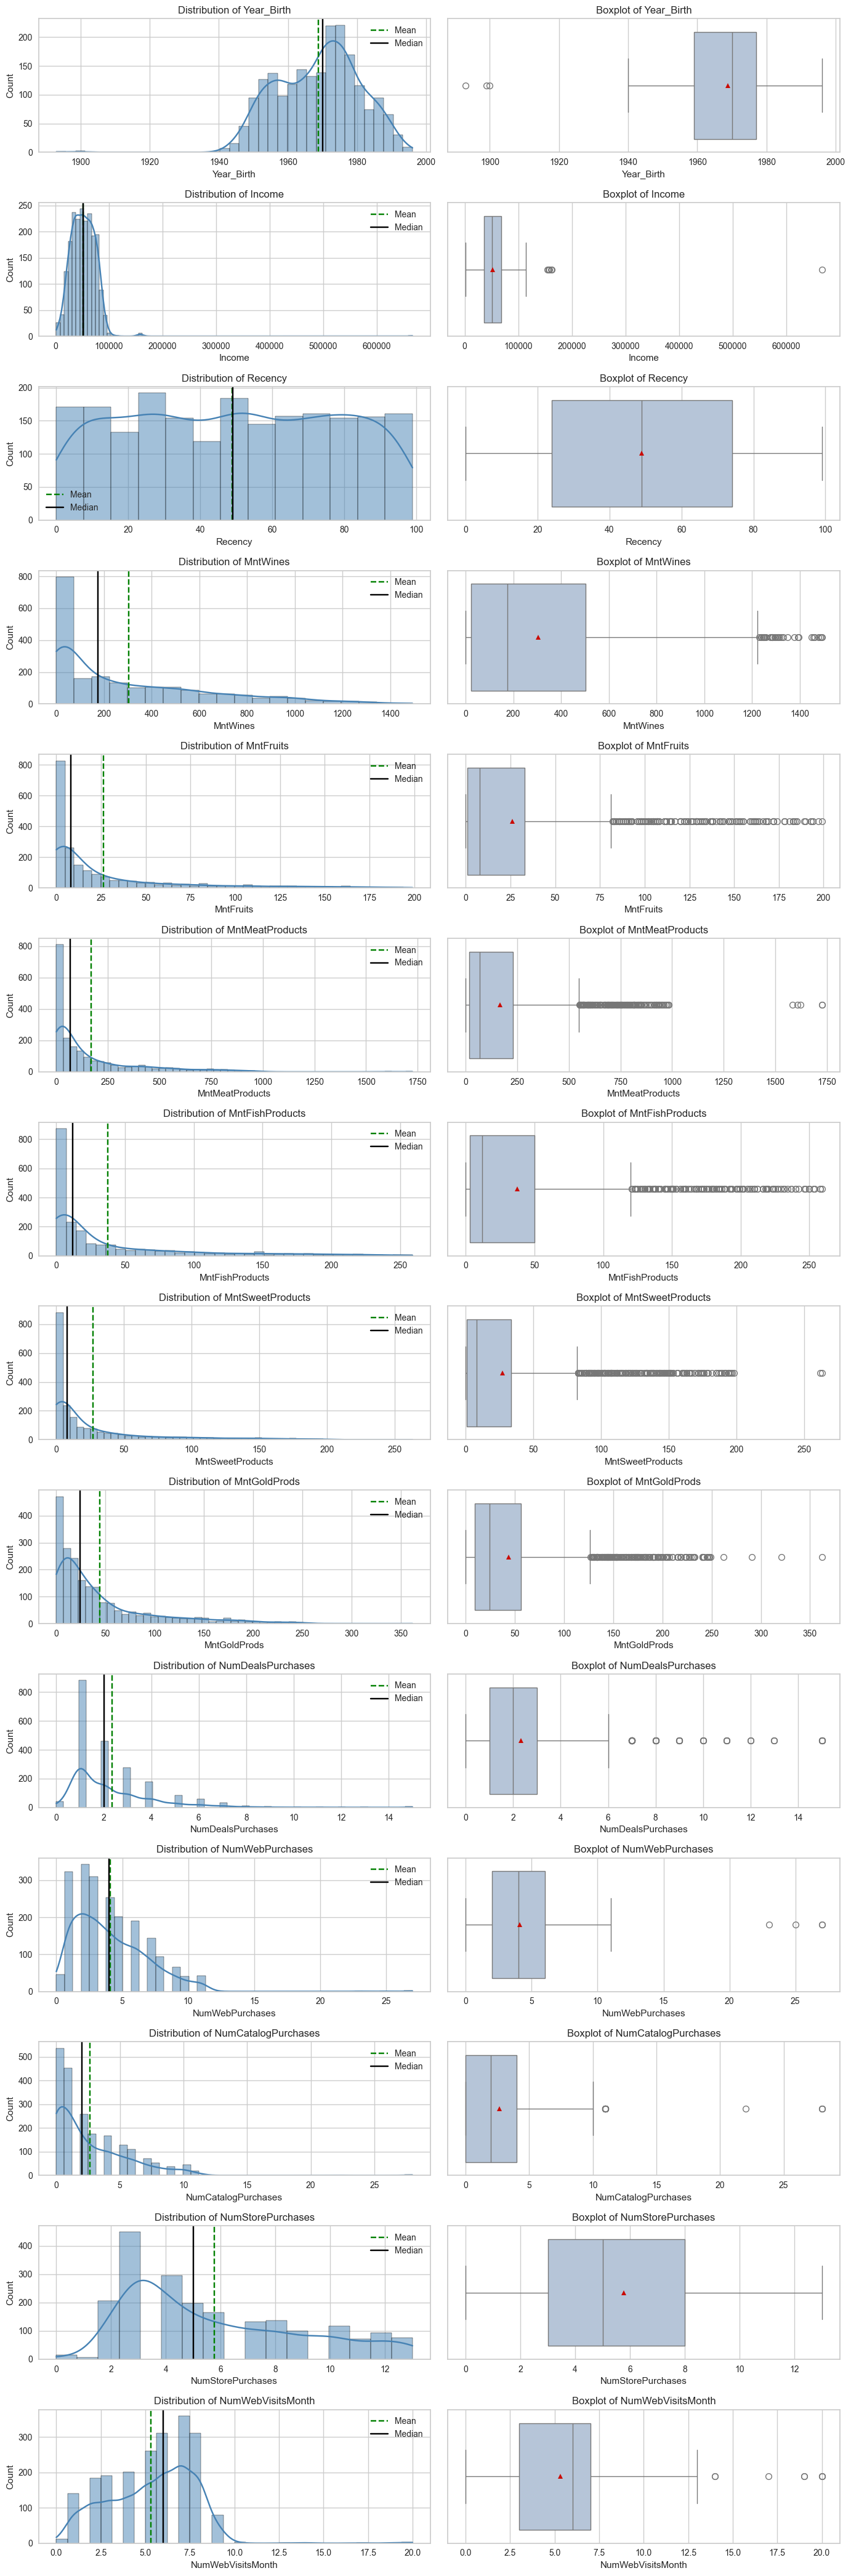

In [189]:
# Continuous / count variables: histogram (with mean and median) + boxplot side by side
num_cols = [
    "Year_Birth", "Income", "Recency",
    "MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds",
    "NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth",
]

fig, axes = plt.subplots(len(num_cols), 2, figsize=(14, 3 * len(num_cols)))

for i, col in enumerate(num_cols):
    # Histogram with mean and median lines
    sns.histplot(data=data, x=col, kde=True, ax=axes[i, 0], color="steelblue")
    axes[i, 0].axvline(data[col].mean(), color="green", linestyle="--", label="Mean")
    axes[i, 0].axvline(data[col].median(), color="black", linestyle="-", label="Median")
    axes[i, 0].set_title(f"Distribution of {col}")
    axes[i, 0].legend()

    # Boxplot (the triangle marks the mean)
    sns.boxplot(data=data, x=col, ax=axes[i, 1], color="lightsteelblue", showmeans=True)
    axes[i, 1].set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

In [190]:
# Skewness of the continuous / count variables (> 1 means strongly right-skewed)
data[num_cols].skew().sort_values(ascending=False).round(2)

Income                 7.10
NumDealsPurchases      2.44
MntSweetProducts       2.15
MntFruits              2.11
MntMeatProducts        2.10
NumCatalogPurchases    1.95
MntFishProducts        1.93
MntGoldProds           1.91
NumWebPurchases        1.43
MntWines               1.17
NumStorePurchases      0.70
NumWebVisitsMonth      0.25
Recency                0.00
Year_Birth            -0.38
dtype: float64

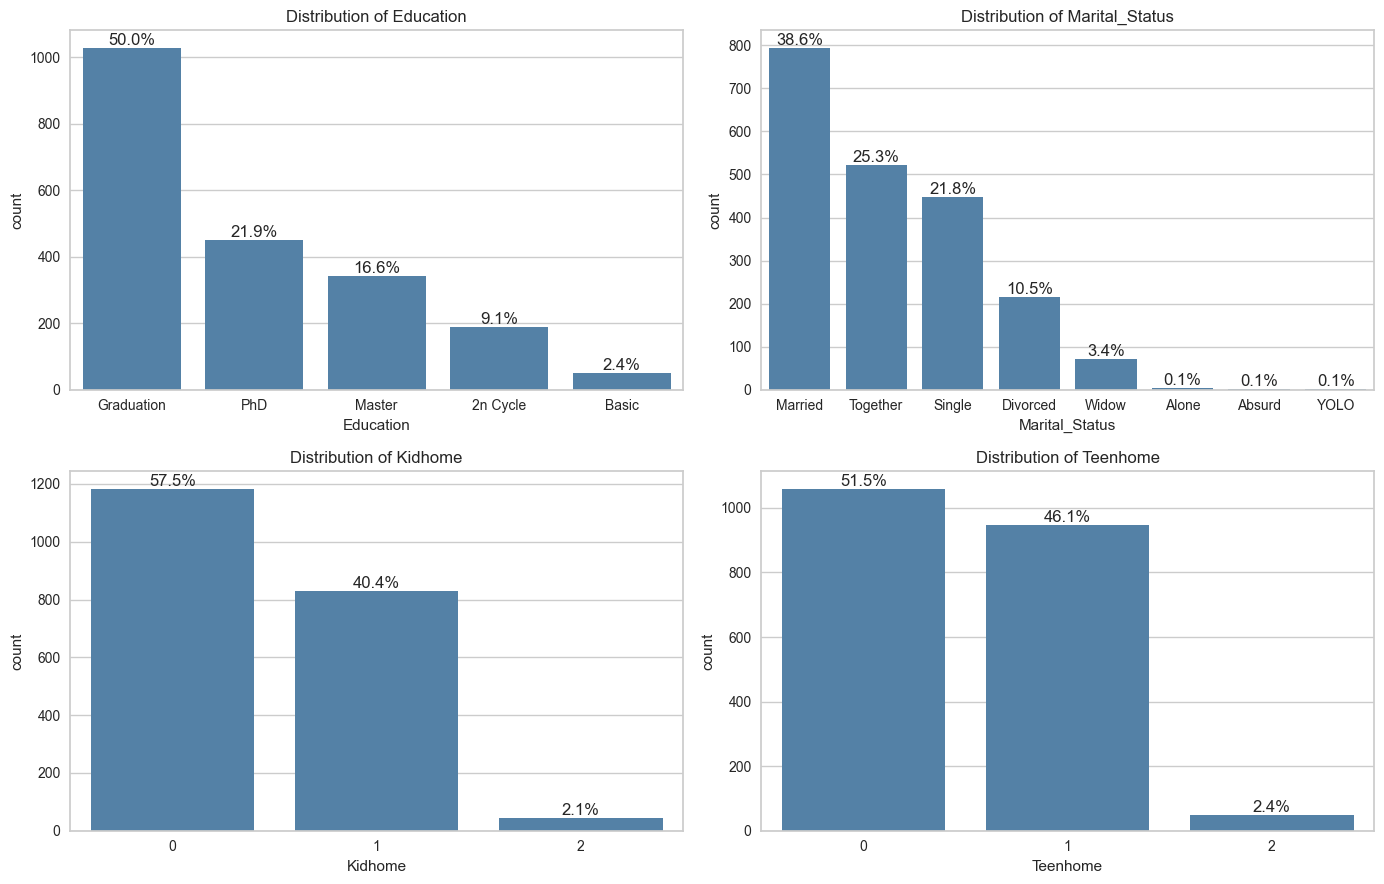

In [191]:
# Categorical and low-cardinality variables: count plots with percentages
cat_cols = ["Education", "Marital_Status", "Kidhome", "Teenhome"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, col in zip(axes.flatten(), cat_cols):
    order = data[col].value_counts().index
    sns.countplot(data=data, x=col, order=order, ax=ax, color="steelblue")
    ax.set_title(f"Distribution of {col}")

    # Annotate each bar with its percentage of customers
    for p in ax.patches:
        pct = 100 * p.get_height() / len(data)
        ax.annotate(f"{pct:.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom")

plt.tight_layout()
plt.show()

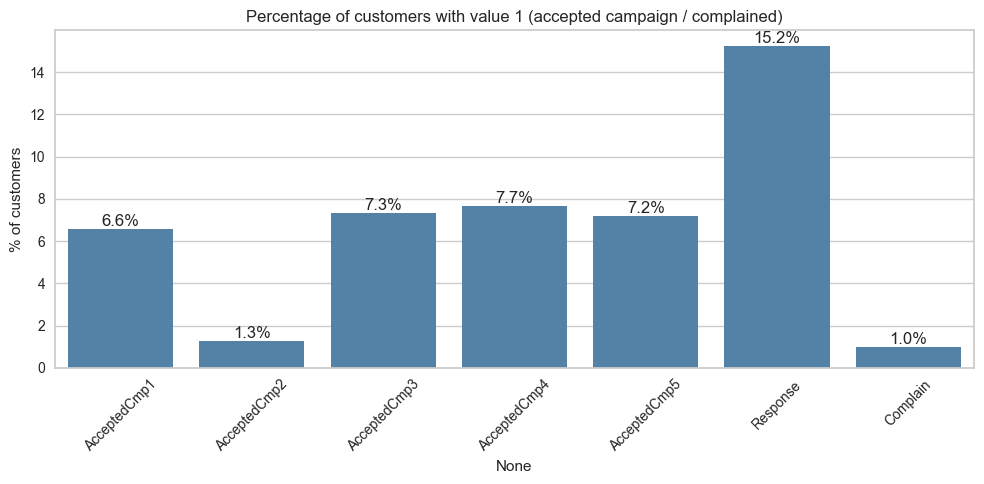

In [192]:
# Binary variables: share of customers who accepted each campaign / complained
bin_cols = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5",
            "Response", "Complain"]
rates = (data[bin_cols].mean() * 100).round(2)

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=rates.index, y=rates.values, color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.title("Percentage of customers with value 1 (accepted campaign / complained)")
plt.ylabel("% of customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Enrollment period: 2012-07-30 to 2014-06-29


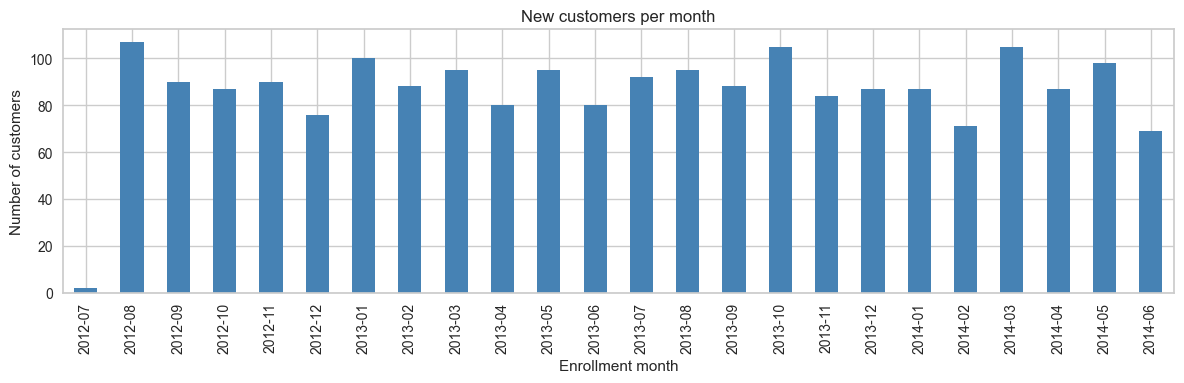

Z_CostContact    1
Z_Revenue        1
dtype: int64


In [193]:
# Enrollment date: number of new customers per month
enroll_dates = pd.to_datetime(data["Dt_Customer"], format="%d-%m-%Y")
print(f"Enrollment period: {enroll_dates.min().date()} to {enroll_dates.max().date()}")

plt.figure(figsize=(12, 4))
enroll_dates.dt.to_period("M").value_counts().sort_index().plot(kind="bar", color="steelblue")
plt.title("New customers per month")
plt.xlabel("Enrollment month")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

# Undocumented columns: check how many distinct values they have
print(data[["Z_CostContact", "Z_Revenue"]].nunique())

##### **Observations:**
- Income is the most skewed variable (skewness 7.1) because of the extreme outlier (666,666). The rest of incomes concentrate between ~35k and ~68k.
- Year_Birth has 3 implausible values (1893, 1899, 1900, i.e. ages over 110) that look like data entry errors.
- Spending (Mnt*) is strongly right-skewed: most customers spend little, while a small group spends a lot. Wine and meat are by far the largest categories. The boxplot outliers are real high spenders, not errors.
- Purchases: stores are the main channel, followed by web and catalog. Most customers make only a few discount purchases.
- Recency is roughly uniform between 0 and 99 days.
- Demographics: 50% of customers have a Graduation degree, and ~64% are Married or Together. Marital_Status contains invalid categories (Alone, Absurd, YOLO).
- Children: more than half of the households have no kids or no teens.
- Campaigns: acceptance is low (1–8% per campaign). The last campaign (Response) performed best at 15.2%. Only 1% of customers complained.
- Enrollment is spread evenly from July 2012 to June 2014 (~90 new customers per month).
- Z_CostContact and Z_Revenue are constant, so they carry no information and I will drop them.

Pre-processing needed: treat the outliers in Income and Year_Birth, drop the constant and non-numerical columns (including Marital_Status) and scale the data before K-means.

### Bivariate Analysis

#### **Question 6:** Perform multivariate analysis to explore the relationships between the variables.

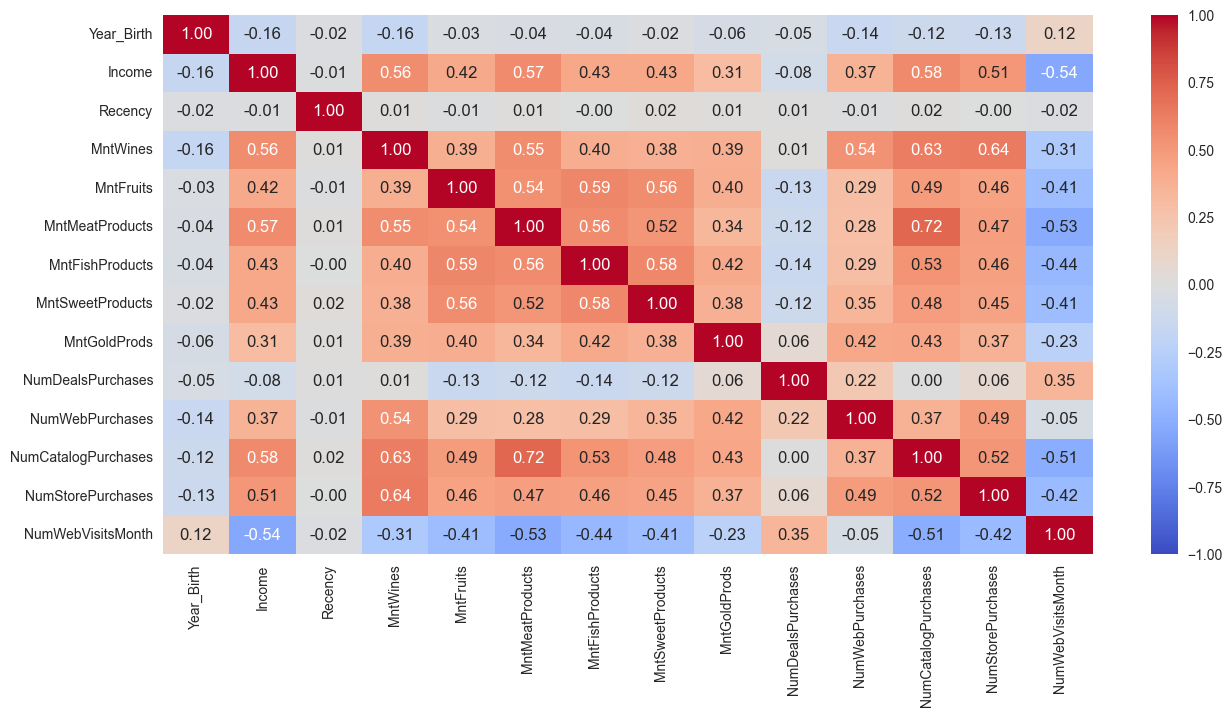

In [194]:
# Correlation heatmap of the numerical variables (num_cols defined in Q5)
plt.figure(figsize=(15, 7))
sns.heatmap(data[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

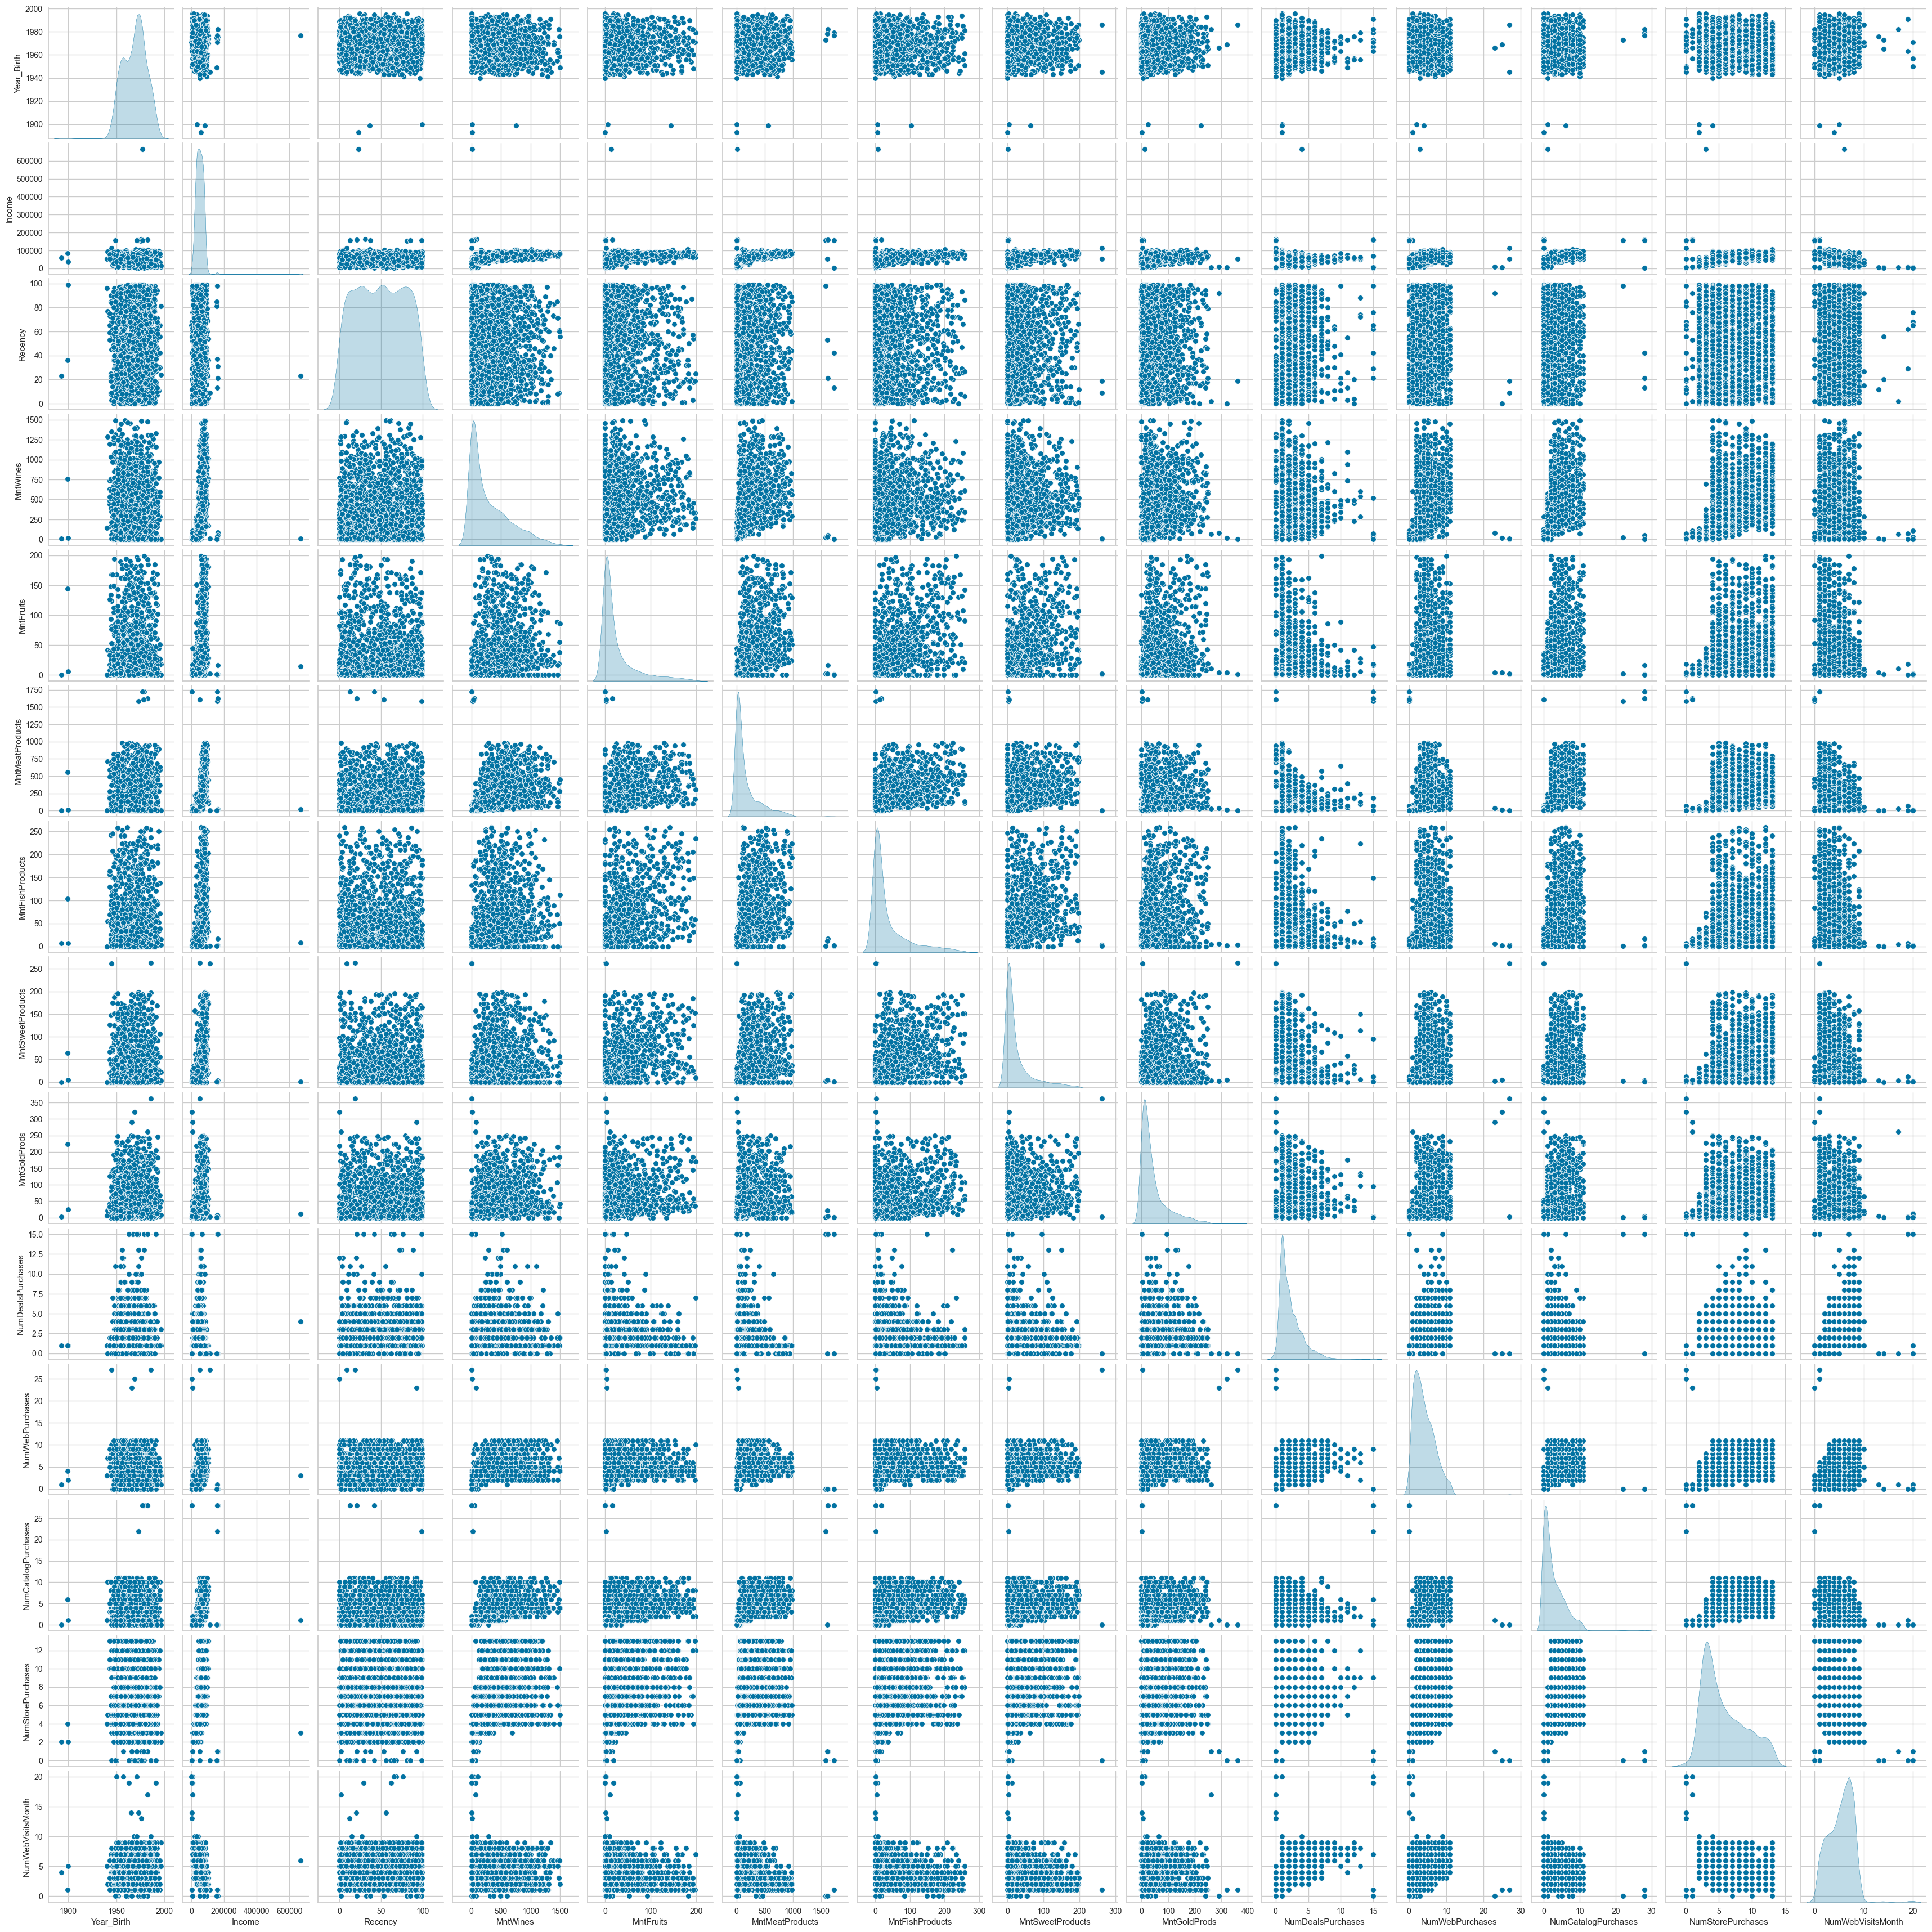

In [195]:
# Pairplot of the numerical variables
sns.pairplot(data=data[num_cols], diag_kind="kde")
plt.show()

##### **Observations:**
- Income is positively correlated with all spending categories (0.4–0.6) and with catalog and store purchases. Higher-income customers spend more.
- Spending categories are correlated with each other (0.4–0.7). Customers who spend a lot on one product tend to spend a lot on the others.
- NumWebVisitsMonth is negatively correlated with income (-0.54) and spending. Frequent web visitors tend to be lower-value customers.
- Recency shows no correlation with any other variable.
- The pairplot confirms these relationships and shows the strong right skew of the spending variables.

## **Data Preprocessing**

### Outlier treatment

In [196]:
# Outliers that are data entry errors (not real extreme customers)
print("Year_Birth before 1940:\n", data.loc[data["Year_Birth"] < 1940, ["ID", "Year_Birth"]], "\n")
print("Income above 200k:\n", data.loc[data["Income"] > 200_000, ["ID", "Income"]])

Year_Birth before 1940:
         ID  Year_Birth
190   7829        1900
237  11004        1893
335   1150        1899 

Income above 200k:
         ID    Income
2053  9432  666666.0


In [197]:
# Remove the implausible birth years (ages over 110) and the extreme income (666,666)
data = data[(data["Year_Birth"] >= 1940) & (data["Income"] <= 200_000)].reset_index(drop=True)
print(f"Shape after removing outliers: {data.shape}")

Shape after removing outliers: (2054, 29)


### Feature engineering and dropping columns

In [198]:
# Age of the customer, calculated at the last enrollment year of the dataset (2014)
reference_year = pd.to_datetime(data["Dt_Customer"], format="%d-%m-%Y").dt.year.max()
data["Age"] = reference_year - data["Year_Birth"]
data["Age"].describe()

count    2054.000000
mean       45.112463
std        11.667729
min        18.000000
25%        37.000000
50%        44.000000
75%        55.000000
max        74.000000
Name: Age, dtype: float64

In [199]:
# Drop columns that are not useful for clustering:
# - ID: identifier only
# - Z_CostContact, Z_Revenue: constant values
# - Year_Birth: replaced by Age
# - Dt_Customer, Education, Marital_Status: non-numerical
# - AcceptedCmp1-5: binary with very low acceptance rates
columns_to_drop = ["ID", "Z_CostContact", "Z_Revenue", "Year_Birth", "Dt_Customer",
                   "Education", "Marital_Status",
                   "AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5"]
data = data.drop(columns=columns_to_drop)

print(f"Shape after dropping columns: {data.shape}")
data.head()

Shape after dropping columns: (2054, 18)


,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age
0,58138.0,0,0,58,635,88,546,172,88,88,3,8,10,4,7,0,1,57
1,46344.0,1,1,38,11,1,6,2,1,6,2,1,1,2,5,0,0,60
2,71613.0,0,0,26,426,49,127,111,21,42,1,8,2,10,4,0,0,49
3,26646.0,1,0,26,11,4,20,10,3,5,2,2,0,4,6,0,0,30
4,58293.0,1,0,94,173,43,118,46,27,15,5,5,3,6,5,0,0,33


### Scaling

In [200]:
# Scaling the data before clustering (z-score: mean 0, standard deviation 1)
scaler = StandardScaler()
subset = data.copy()
subset_scaled = scaler.fit_transform(subset)

In [201]:
# Creating a dataframe of the scaled data
subset_scaled_data = pd.DataFrame(subset_scaled, columns=subset.columns)
subset_scaled_data.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Income,2054.0,-0.0,1.0,-2.34,-0.76,-0.03,0.75,5.14
Kidhome,2054.0,-0.0,1.0,-0.83,-0.83,-0.83,1.03,2.89
Teenhome,2054.0,0.0,1.0,-0.93,-0.93,-0.93,0.90,2.73
Recency,2054.0,0.0,1.0,-1.69,-0.86,0.00,0.86,1.73
MntWines,2054.0,0.0,1.0,-0.90,-0.84,-0.39,0.59,3.53
MntFruits,2054.0,0.0,1.0,-0.66,-0.64,-0.46,0.17,4.35
MntMeatProducts,2054.0,0.0,1.0,-0.73,-0.66,-0.44,0.27,6.82
MntFishProducts,2054.0,0.0,1.0,-0.68,-0.63,-0.46,0.23,4.05
MntSweetProducts,2054.0,0.0,1.0,-0.65,-0.63,-0.46,0.16,5.65
MntGoldProds,2054.0,0.0,1.0,-0.84,-0.67,-0.38,0.23,6.12


##### **Observations:**
- I removed 4 rows with data entry errors: 3 customers with Year_Birth before 1940 (ages over 110) and 1 customer with an income of 666,666. The dataset now has 2,054 customers.
- I kept the high spenders seen as outliers in the boxplots, because they are real customers and a relevant segment.
- I created Age (at 2014, the last enrollment year) to replace Year_Birth.
- I dropped 12 columns that are not useful for clustering: identifiers (ID), constants (Z_CostContact, Z_Revenue), non-numerical columns (Dt_Customer, Education, Marital_Status), Year_Birth (replaced by Age) and AcceptedCmp1-5 (very low acceptance rates). 18 numerical features remain.
- After scaling with StandardScaler, every feature has mean 0 and standard deviation 1, so no variable dominates the distance calculation in K-means because of its scale.

## **K-means Clustering**

#### **Question 7** : Select the appropriate number of clusters using the elbow Plot. What do you think is the appropriate number of clusters?

Number of clusters: 2 	WCSS: 26,887.56
Number of clusters: 3 	WCSS: 23,827.94
Number of clusters: 4 	WCSS: 22,830.22
Number of clusters: 5 	WCSS: 21,841.41
Number of clusters: 6 	WCSS: 20,637.33
Number of clusters: 7 	WCSS: 19,929.96
Number of clusters: 8 	WCSS: 18,008.15
Number of clusters: 9 	WCSS: 17,575.10
Number of clusters: 10 	WCSS: 16,995.33


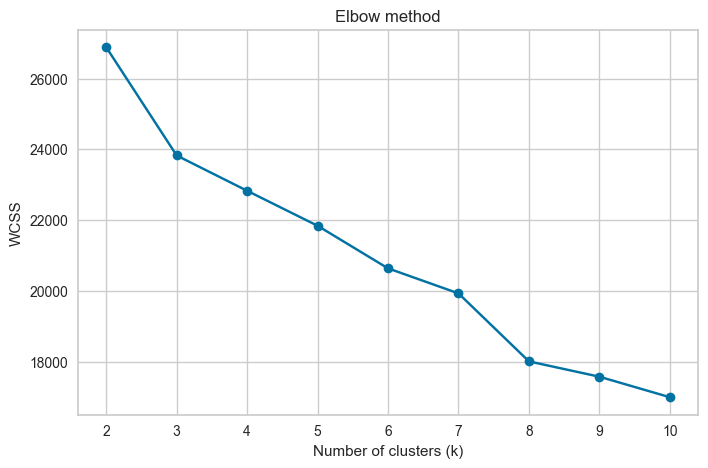

In [202]:
# Copy of the scaled data used for K-means (also used later in cluster profiling)
k_means_data = subset_scaled_data.copy()

# Fit K-means for k = 2..10 and store the within-cluster sum of squares (WCSS)
clusters = range(2, 11)
wcss_list = []

for k in clusters:
    model = KMeans(n_clusters=k, random_state=1)
    model.fit(k_means_data)
    wcss_list.append(model.inertia_)
    print(f"Number of clusters: {k} \tWCSS: {model.inertia_:,.2f}")

# Elbow plot
plt.figure(figsize=(8, 5))
plt.plot(clusters, wcss_list, "bx-", marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("WCSS")
plt.title("Elbow method")
plt.show()

##### **Observations:**
- WCSS decreases as k increases, as expected, but the biggest drop happens from k=2 to k=3 (-11.4%). After that the curve flattens (~3–5% per additional cluster, except for k=8).
- The elbow appears at k=3, so I consider 3 clusters the appropriate number.
- There is a smaller bend at k=8, but 8 segments would be too many to interpret and act on from a business perspective.
- The elbow is not very sharp, so I will confirm the choice with the silhouette score (Q8).

#### **Question 8** : finalize appropriate number of clusters by checking the silhouette score as well. Is the answer different from the elbow plot?

In [203]:
# Silhouette score for k = 2..9 (closer to 1 means better separated clusters)
sil_score = []
cluster_list = range(2, 10)

for n_clusters in cluster_list:
    clusterer = KMeans(n_clusters=n_clusters, random_state=1)
    preds = clusterer.fit_predict(k_means_data)
    score = silhouette_score(k_means_data, preds)
    sil_score.append(score)
    print(f"For n_clusters = {n_clusters}, the silhouette score is {score:.4f}")

For n_clusters = 2, the silhouette score is 0.2834
For n_clusters = 3, the silhouette score is 0.2112
For n_clusters = 4, the silhouette score is 0.1890
For n_clusters = 5, the silhouette score is 0.1894
For n_clusters = 6, the silhouette score is 0.1454
For n_clusters = 7, the silhouette score is 0.1457
For n_clusters = 8, the silhouette score is 0.1535
For n_clusters = 9, the silhouette score is 0.1290


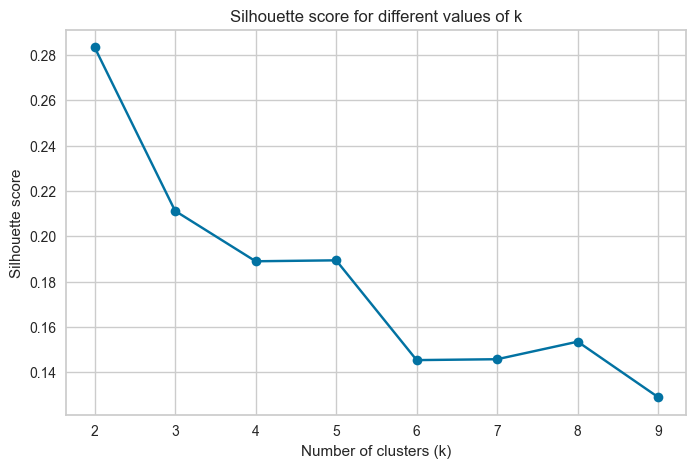

In [204]:
# Silhouette score plot
plt.figure(figsize=(8, 5))
plt.plot(cluster_list, sil_score, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette score for different values of k")
plt.show()

##### **Observations:**
- The highest silhouette score is for k=2 (0.28), followed by k=3 (0.21). From k=4 onwards the score generally decreases.
- So the answer is slightly different from the elbow plot, which suggested k=3.
- I choose k=3 because:
  - it is the elbow point and has the second-best silhouette score;
  - 2 clusters would only separate high and low spenders, which is too broad for personalized marketing;
  - it gives balanced segments of a manageable size.
- The silhouette scores are low overall (< 0.3), so the clusters overlap to some degree, which is common in customer data.

#### **Question 9**: Do a final fit with the appropriate number of clusters. How much total time does it take for the model to fit the data?

In [205]:
%%time
# Final K-means fit with the selected number of clusters (k=3)
# random_state=1 for consistency with the elbow and silhouette analysis
kmeans = KMeans(n_clusters=3, random_state=1)
kmeans.fit(k_means_data)

CPU times: user 20 ms, sys: 16.3 ms, total: 36.3 ms
Wall time: 20.4 ms


KMeans(n_clusters=3, random_state=1)

In [206]:
# Creating a copy of the original (unscaled) data
data1 = data.copy()

# Adding the K-means cluster labels to the original and scaled dataframes
k_means_data["K_means_segments"] = kmeans.labels_
data1["K_means_segments"] = kmeans.labels_

# Number of customers in each cluster
data1["K_means_segments"].value_counts().sort_index()

K_means_segments
0    593
1    923
2    538
Name: count, dtype: int64

##### **Observations:**
- I fitted the final K-means model with k=3.
- The fit took 20.4 ms of wall time (total CPU time: 36.3 ms). K-means is very fast on this dataset (2,054 customers × 18 features), so computational cost is not a concern.
- The clusters are reasonably balanced: 593, 923 and 538 customers.
- I stored the cluster labels in data1 (original scale) to profile and interpret each segment in the next questions.

## **Cluster Profiling and Comparison**

#### **Question 10**: Perform cluster profiling using boxplots for the K-Means algorithm. Analyze key characteristics of each cluster and provide detailed observations.

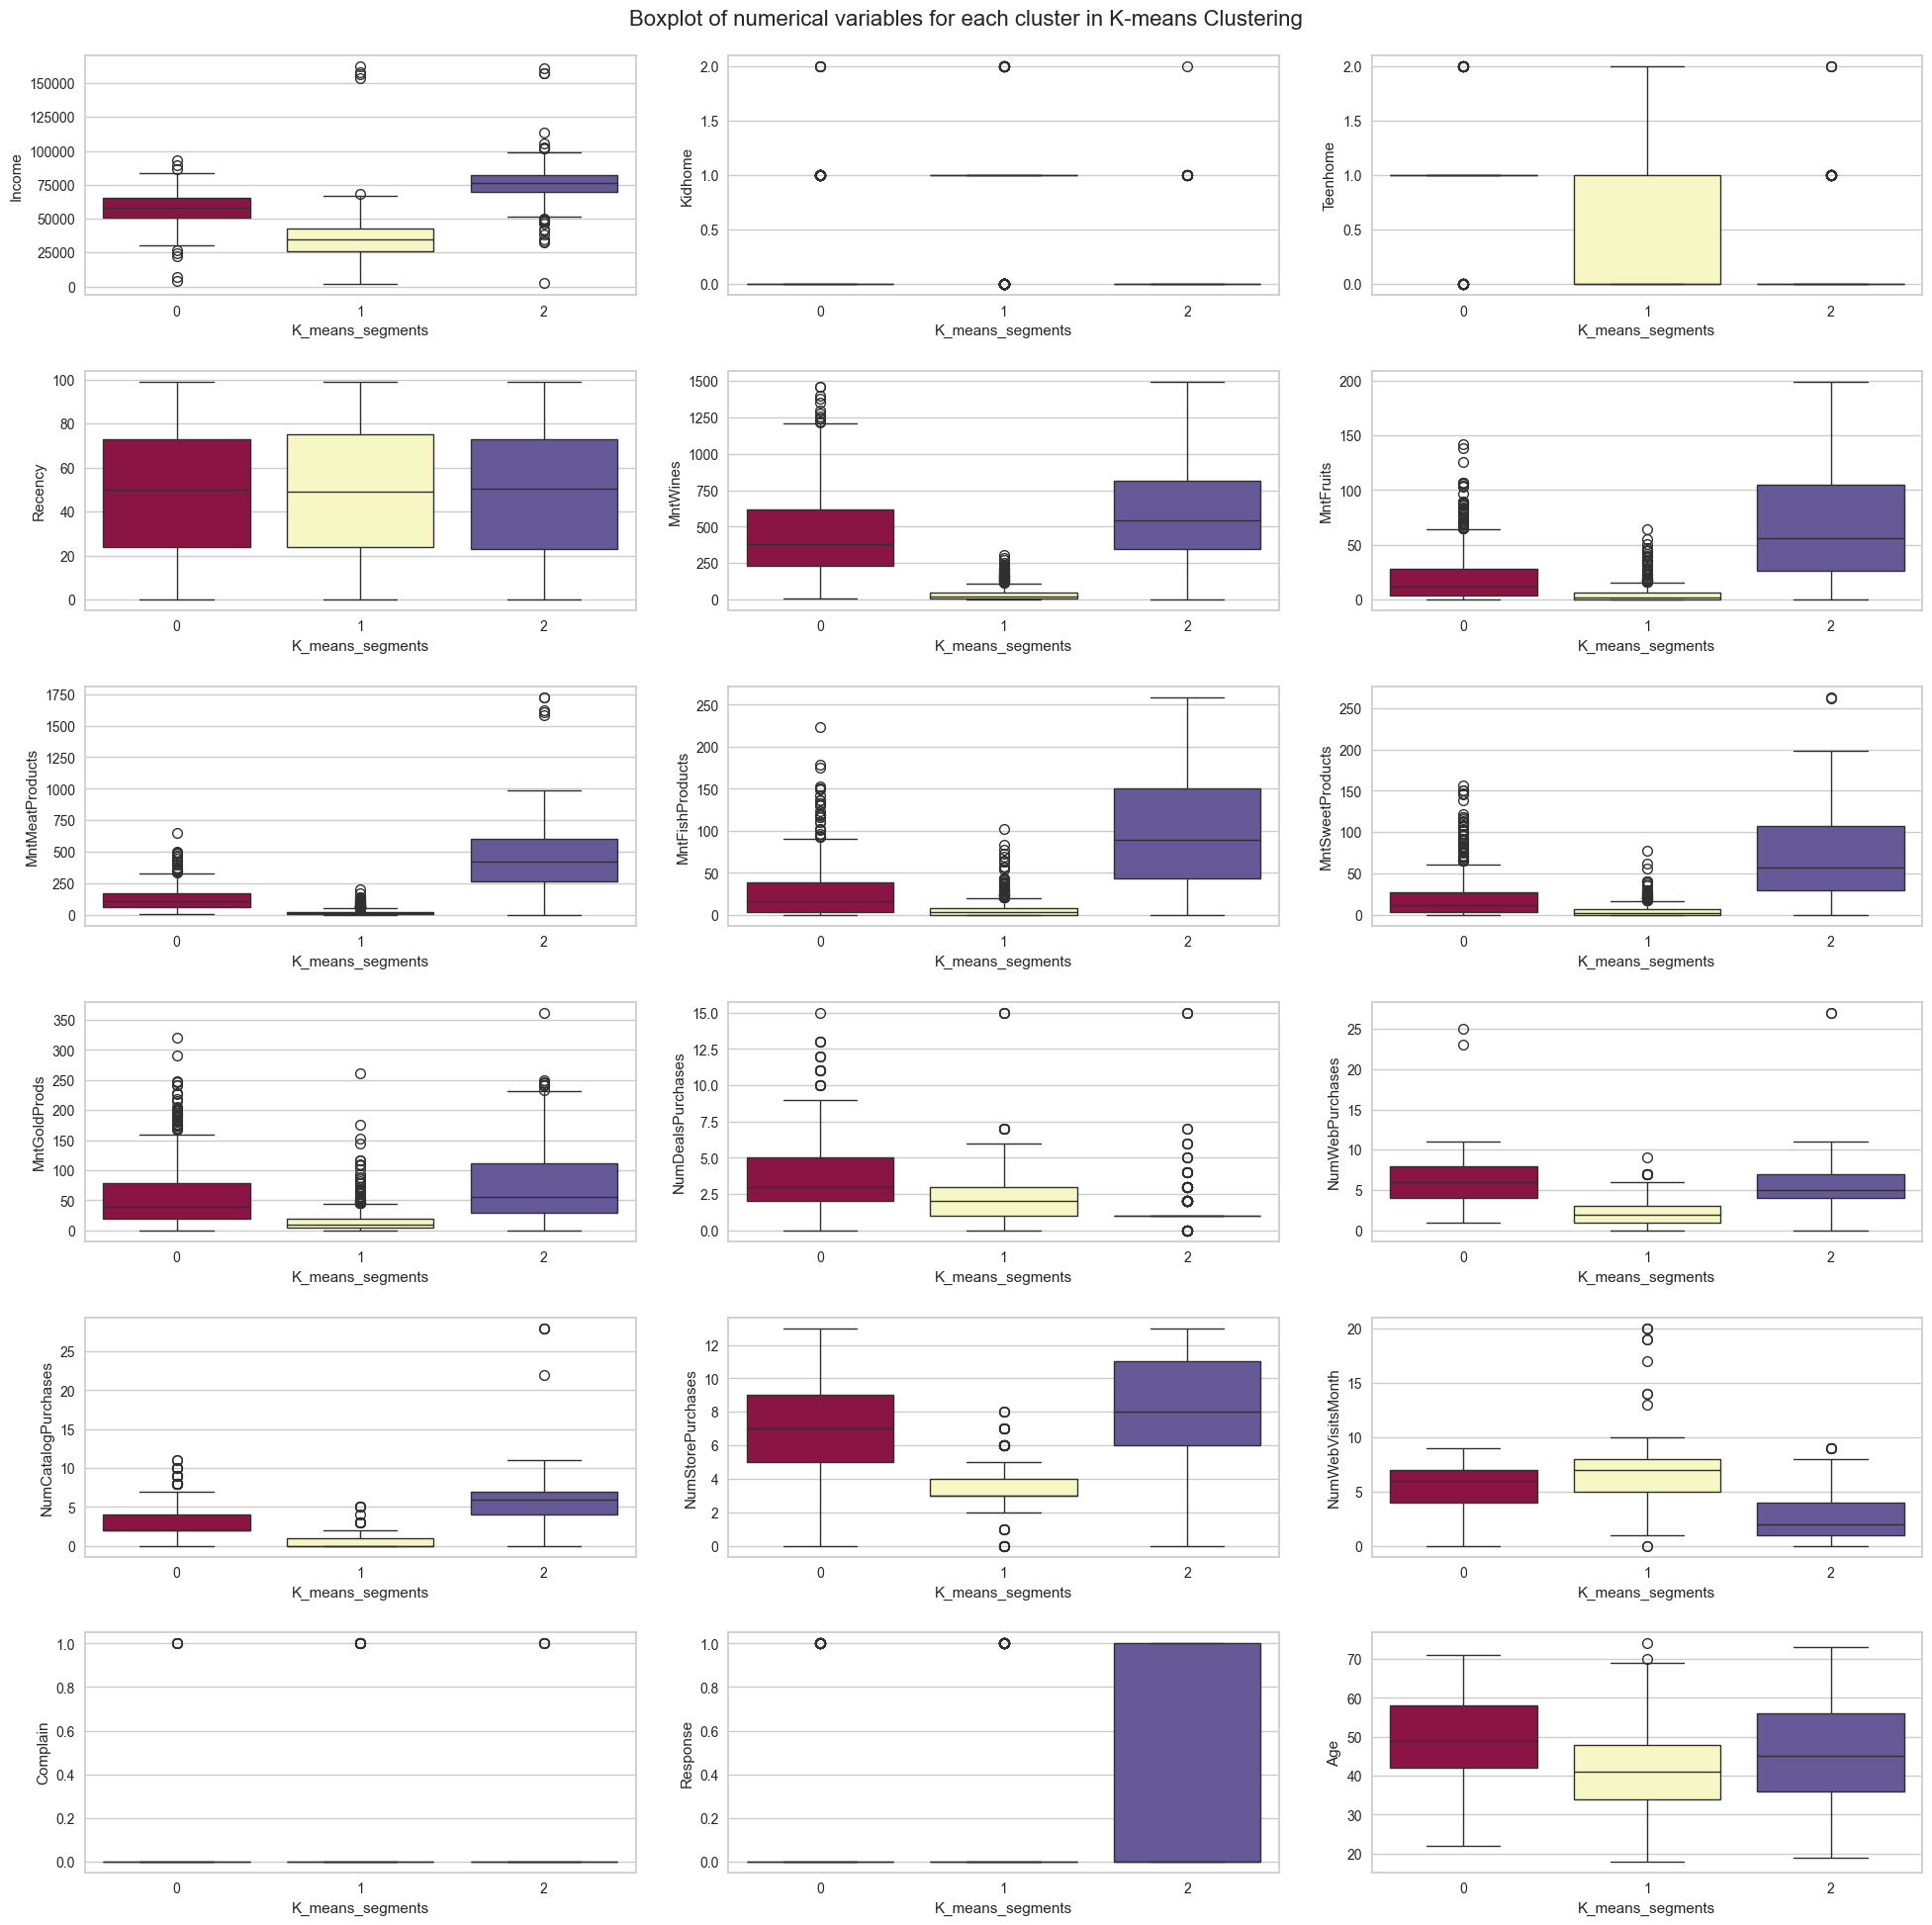

In [207]:
# Boxplots of each variable by cluster, on the original (unscaled) data
plt.figure(figsize=(20, 20))
plt.suptitle("Boxplot of numerical variables for each cluster in K-means Clustering", fontsize=16)

# Iterate over each variable (the last column is the cluster label)
for i, variable in enumerate(data1.columns.to_list()[:-1]):
    plt.subplot(6, 3, i + 1)
    sns.boxplot(data=data1, x="K_means_segments", y=variable, hue="K_means_segments",
                palette="Spectral", legend=False)

plt.tight_layout(pad=2.0)
plt.show()

##### **Observations:**
Cluster 0 – "Established families" (593 customers)
- Middle income (median ~58k) and the oldest group (median age 49).
- Most households have a teenager (median Teenhome = 1) and few small kids.
- Moderate spending (median total ~640), mainly on wine.
- The most frequent deal buyers (median 3 deal purchases) and active on both web and store (6–7 purchases each).

Cluster 1 – "Young budget families" (923 customers, the largest group)
- Lowest income (median ~34k) and the youngest group (median age 41).
- Most households have a small child (median Kidhome = 1).
- Very low spending in every category (median total ~60).
- Few purchases in all channels, but the most web visits per month (median 7). They browse a lot but buy little.

Cluster 2 – "Affluent high spenders" (538 customers)
- Highest income (median ~76k), mostly without children.
- Highest spending in every category (median total ~1,350), especially wine and meat.
- Strongest catalog and store buyers (medians of 6 and 8 purchases), rarely use deals and visit the website the least.
- Most responsive to campaigns: 29% accepted the last one, vs. ~10% in the other clusters.

Common to all clusters
- Recency and complaints barely differ between clusters, so they do not drive the segmentation.
- The main differences come from income, spending, household composition and purchase channel.

#### **Question 11**: Perform cluster profiling on the data using a barplot for the K-Means algorithm. Provide insights and key observations for each cluster based on the visual analysis.

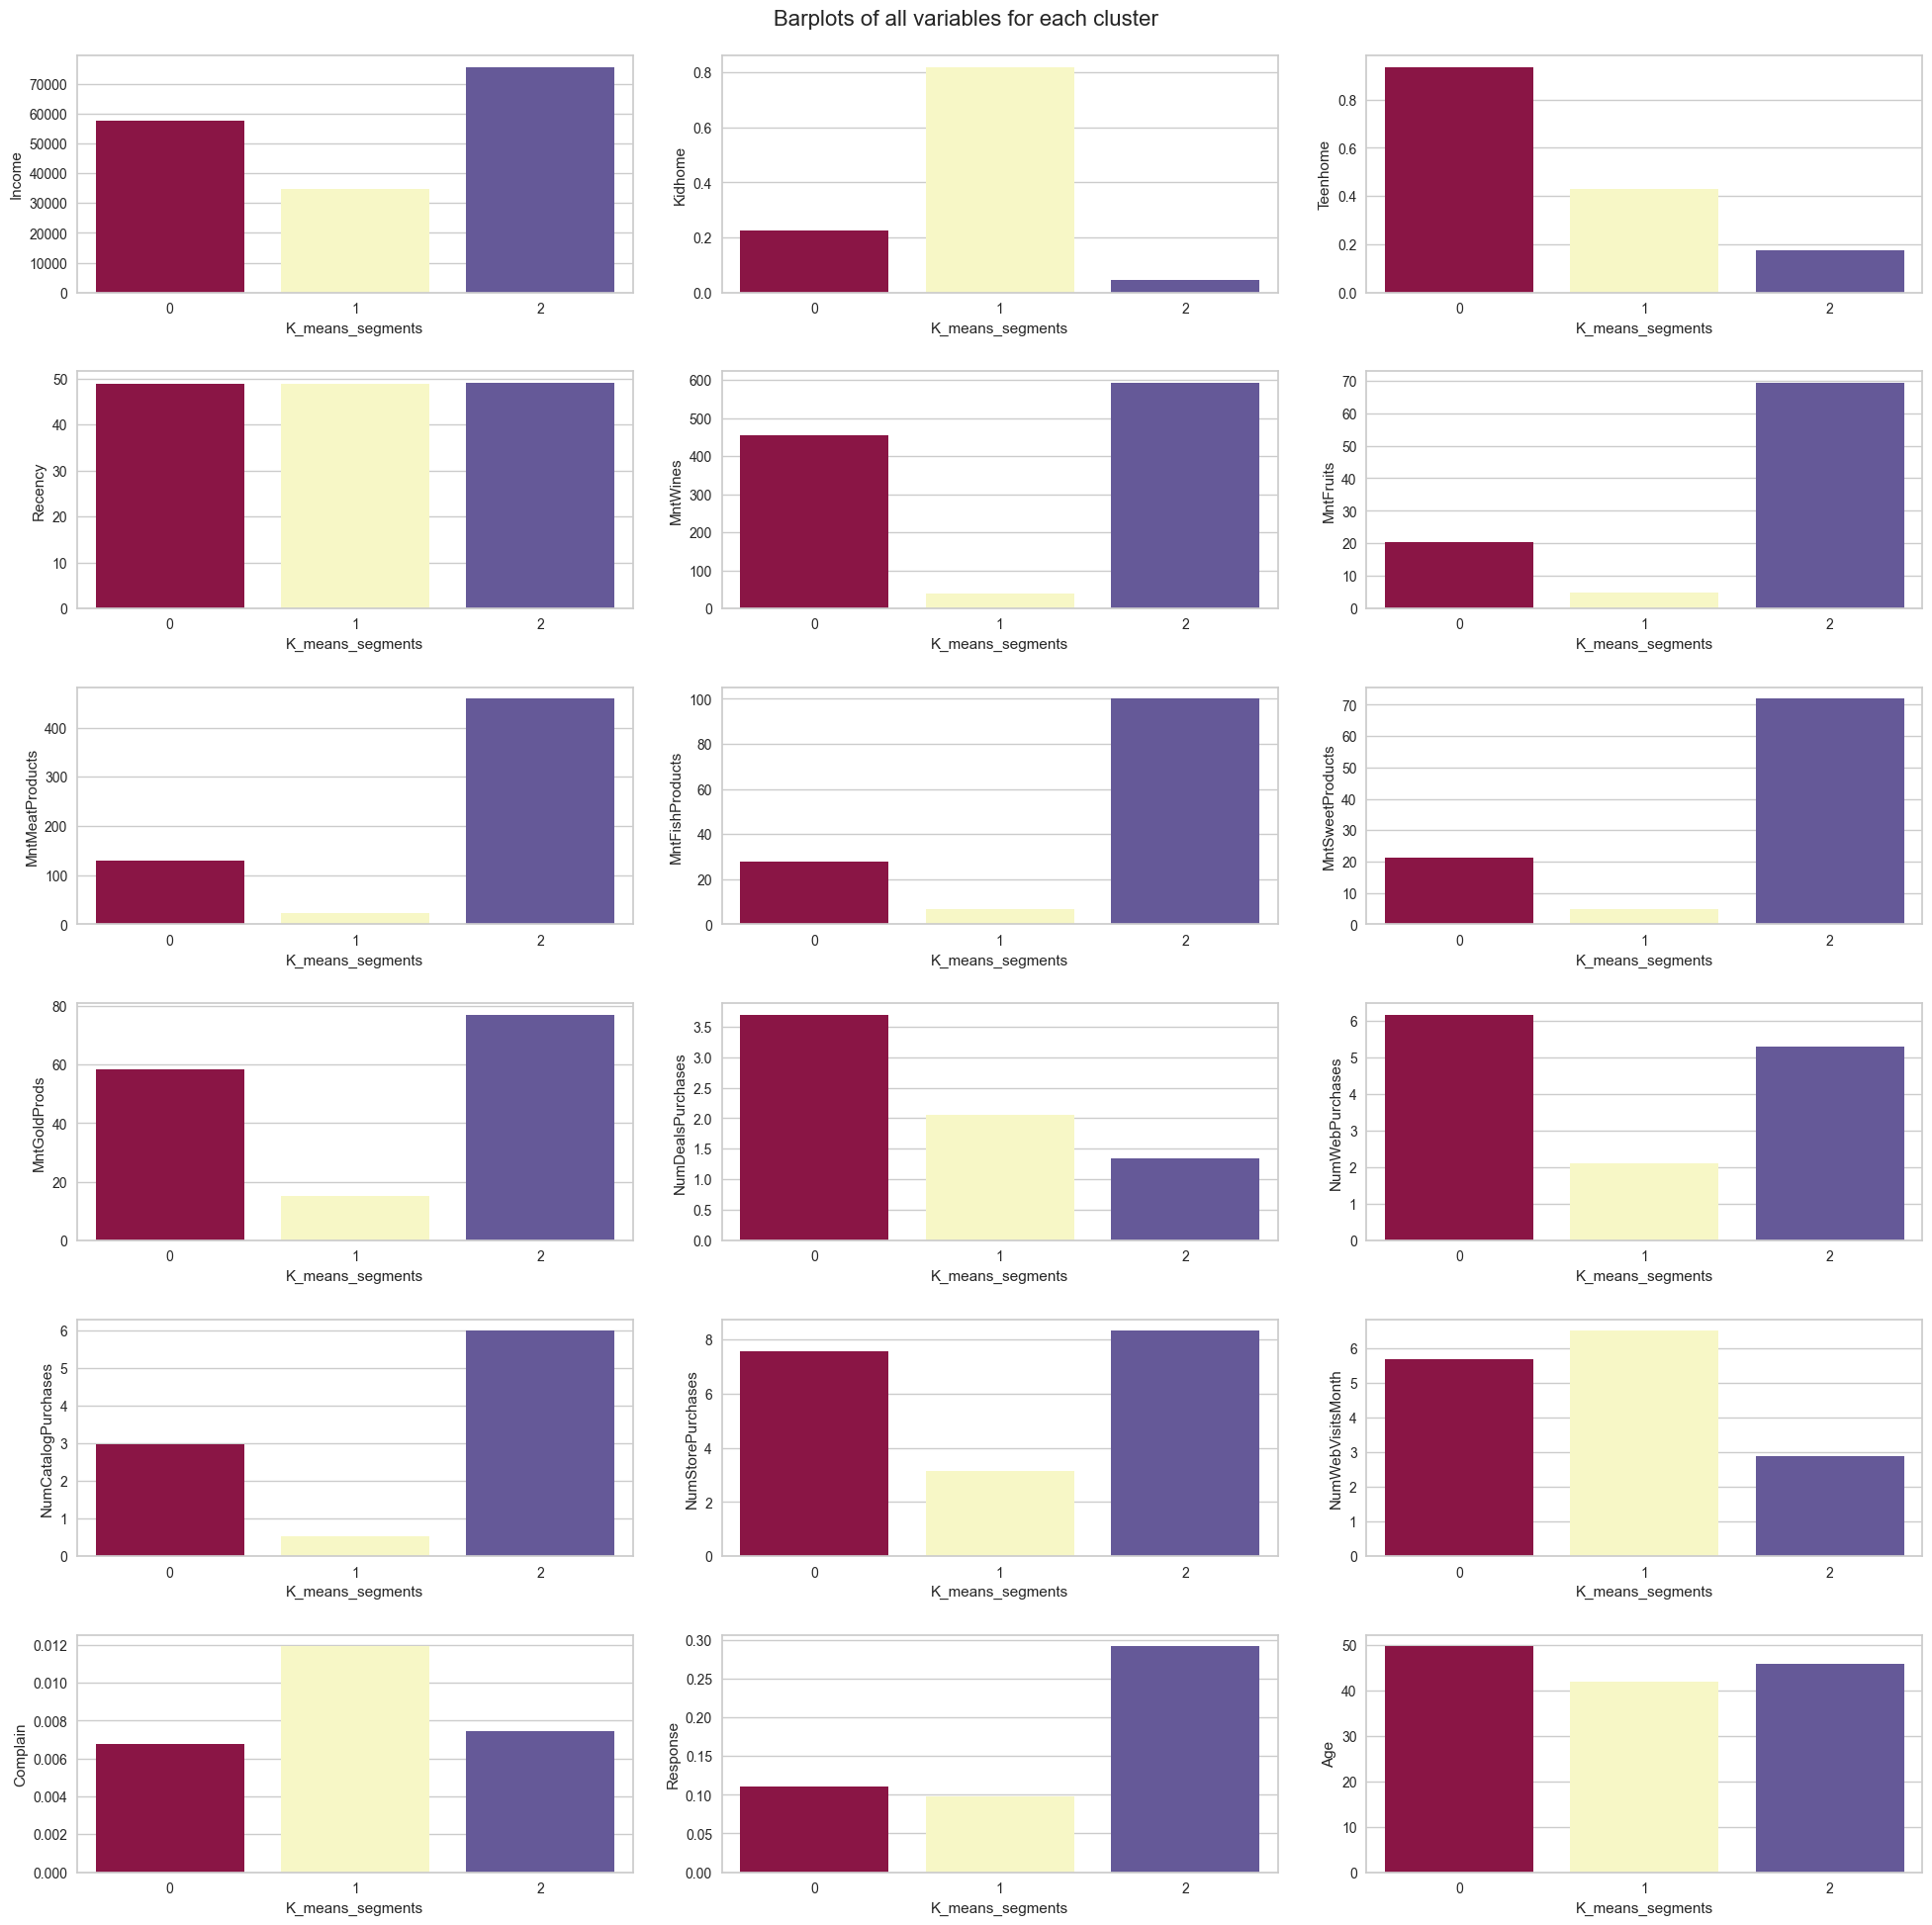

In [208]:
# Barplots of the mean of each variable by cluster, on the original (unscaled) data
plt.figure(figsize=(20, 20))
plt.suptitle("Barplots of all variables for each cluster", fontsize=16)

# Iterate over each variable (the last column of data1 is the cluster label)
for i, variable in enumerate(data1.columns.to_list()[:-1]):
    plt.subplot(6, 3, i + 1)
    sns.barplot(data=data1, x="K_means_segments", y=variable, hue="K_means_segments",
                palette="Spectral", errorbar=None, legend=False)

plt.tight_layout(pad=2.0)
plt.show()

##### **Observations:**
Cluster 0 – "Established families" (593 customers)
- Middle income (~58k on average) and the oldest cluster (~50 years).
- Almost every household has a teenager (0.94 teens on average).
- Second in spending in every category, with wine clearly first (~455).
- The highest use of deals (3.7 purchases) and the most web purchases (6.2). They are value-seeking but engaged buyers.

Cluster 1 – "Young budget families" (923 customers)
- Lowest income (~35k) and the youngest cluster (~42 years), with small kids at home (0.82 on average).
- Very low spending in every category (e.g. ~39 on wine vs. ~590 in Cluster 2).
- Few purchases in every channel but the most web visits (6.5 per month). Their interest does not turn into purchases.

Cluster 2 – "Affluent high spenders" (538 customers)
- Highest income (~76k) and almost no children.
- Leaders in every spending category, especially meat (~460) and wine (~590).
- The most catalog and store purchases, the fewest deal purchases and the fewest web visits.
- The best campaign response rate (29%, about 3 times the other clusters).

Overall
- The barplots confirm the boxplot findings: the clusters are mainly separated by income, spending, children at home and purchase channel.
- Recency is practically the same in all clusters (~49 days), and complaints are very rare (~1%) in all of them.

## **Business Recommendations**

#### **Question 12**: Based on the cluster insights, what business recommendations can be provided?

Business Recommendations:

Cluster 2 – Affluent high spenders (538 customers): retain and grow
- This is the most valuable segment. I recommend a loyalty / VIP program with exclusive benefits, early access to new products and personalized service.
- They respond best to campaigns (29%), buy through catalog and stores and rarely use discounts. Campaigns should focus on premium products (wine and meat), not on price promotions.
- Priority goal: retention, because losing one of these customers has the highest revenue impact.

Cluster 0 – Established families (593 customers): increase basket size
- They spend moderately, are deal-driven and buy actively on the web.
- I recommend bundles and volume discounts on wine and family products, plus personalized online offers based on purchase history.
- Goal: move part of this segment towards the spending level of Cluster 2.

Cluster 1 – Young budget families (923 customers): convert interest into purchases
- This is the largest segment. They visit the website often but buy little, and they have lower income and small kids.
- I recommend affordable product lines, entry-level promotions and kid-oriented products, together with retargeting of web visitors (e.g. reminders and first-purchase coupons).
- Marketing spend here should stay low-cost and digital, because their current value is low.

General recommendations
- Resource allocation: concentrate the premium marketing budget on Cluster 2, use promotional campaigns for Cluster 0 and low-cost digital channels for Cluster 1.
- Implementation: assign every new customer to a segment with the trained model and re-train it periodically (e.g. every 6 months), as customer behavior changes.
- Additional data: product-level transactions, customer lifetime value, online browsing behavior and customer satisfaction would make the segments richer and more actionable.
- Model improvements: test other algorithms (e.g. hierarchical clustering or Gaussian Mixture Models), reduce correlated features (e.g. total spending instead of six Mnt* variables) and include categorical variables such as education. Better-separated segments would make targeting more precise and reduce wasted marketing spend.
- Measuring results: run A/B tests of the segment-specific campaigns to quantify the gain in conversion rate and revenue.